In [1]:
!pip install torch torchvision h5py numpy scikit-learn matplotlib tqdm --quiet


In [3]:
import h5py
import numpy as np

hf = h5py.File(r"C:\multimodal_imdb.hdf5", "r")

images = hf['images']        
labels = hf['genres']       

print("Loaded images shape:", images.shape)
print("Loaded labels shape:", labels.shape)


Loaded images shape: (25959, 3, 256, 160)
Loaded labels shape: (25959, 23)


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np


num_samples = labels.shape[0]
all_indices = np.arange(num_samples)

train_idx, test_idx = train_test_split(all_indices, test_size=0.2, random_state=42)
val_idx, test_idx = train_test_split(test_idx, test_size=0.5, random_state=42)

print(f"Splits → Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")


Splits → Train: 20767, Val: 2596, Test: 2596


In [5]:
from torch.utils.data import Dataset
from torchvision.transforms import ToTensor, Normalize, Compose, Resize, ToPILImage

class PosterGenreDataset(Dataset):
    def __init__(self, images, labels, indices, transform=None):
        self.images = images           
        self.labels = labels           
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]

        img = self.images[real_idx].astype(np.uint8).transpose(1, 2, 0)
        label = self.labels[real_idx].astype(np.float32)

        if self.transform:
            img = self.transform(img)

        return img, label


In [6]:
from torchvision import transforms

image_transforms = transforms.Compose([
    ToPILImage(),
    Resize((224, 224)),
    ToTensor(),
    Normalize(mean=[0.485, 0.456, 0.406],
              std=[0.229, 0.224, 0.225])
])

train_dataset = PosterGenreDataset(images, labels, train_idx, transform=image_transforms)
val_dataset   = PosterGenreDataset(images, labels, val_idx, transform=image_transforms)
test_dataset  = PosterGenreDataset(images, labels, test_idx, transform=image_transforms)

from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32)
test_loader  = DataLoader(test_dataset, batch_size=32)

print("Dataloaders ready!")


Dataloaders ready!


In [7]:
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = mobilenet_v2(pretrained=True)

model.classifier[1] = nn.Sequential(
    nn.Linear(model.last_channel, 23), 
    nn.Sigmoid()  
)

model = model.to(device)
print("MobileNetV2 is ready on", device)


MobileNetV2 is ready on cpu


C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [9]:
import torch.optim as optim

criterion = nn.BCELoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-4)

def train_model(model, train_loader, val_loader, epochs=3):
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for imgs, labels in train_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {avg_loss:.4f}")

        model.eval()
val_loss = 0.0
with torch.no_grad():
    for i, (imgs, labels) in enumerate(val_loader):
        imgs = imgs.to(device)
        labels = labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        val_loss += loss.item()
        
        if i == 4:  
            break

print(f"Quick Val Loss (5 batches): {val_loss / 5:.4f}")


Quick Val Loss (5 batches): 0.7477


In [10]:
from sklearn.metrics import accuracy_score, f1_score, hamming_loss, classification_report
import numpy as np
import torch

def evaluate_model(model, dataloader, device='cpu', threshold=0.5):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)
            preds = (outputs > threshold).int()

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    y_pred = np.vstack(all_preds)
    y_true = np.vstack(all_labels)

    print("Evaluation Complete")
    print("Hamming Loss:", hamming_loss(y_true, y_pred))
    print("F1 Score (micro):", f1_score(y_true, y_pred, average='micro'))
    print("F1 Score (macro):", f1_score(y_true, y_pred, average='macro'))
    print("Accuracy (subset):", accuracy_score(y_true, y_pred)) 
    return y_true, y_pred  

In [11]:
y_true, y_pred = evaluate_model(model, test_loader, device=device)


Evaluation Complete
Hamming Loss: 0.5614155557044282
F1 Score (micro): 0.13451756990524386
F1 Score (macro): 0.11931614348313409
Accuracy (subset): 0.0


In [12]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.52      0.10      0.17      1410
           1       0.37      0.33      0.35       855
           2       0.20      0.94      0.33       518
           3       0.22      0.03      0.06       529
           4       0.14      0.04      0.07       394
           5       0.10      0.29      0.15       361
           6       0.10      0.24      0.14       252
           7       0.10      0.71      0.18       276
           8       0.08      0.57      0.14       208
           9       0.09      0.79      0.17       229
          10       0.07      0.79      0.13       189
          11       0.08      0.98      0.14       196
          12       0.07      0.99      0.12       167
          13       0.05      0.87      0.10       135
          14       0.04      0.06      0.05       145
          15       0.04      0.47      0.07       118
          16       0.04      0.85      0.07       100
          17       0.06    

In [13]:
print(y_true.shape)


(2596, 23)


In [14]:
genre_names = [
    "Action", "Adventure", "Animation", "Biography", "Comedy", "Crime",
    "Documentary", "Drama", "Family", "Fantasy", "History", "Horror",
    "Music", "Musical", "Mystery", "News", "Romance", "Sci-Fi", "Short",
    "Sport", "Thriller", "War", "Western"
]

def get_probs_and_labels(model, dataloader, device='cpu'):
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)  
            all_probs.append(outputs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    y_prob = np.vstack(all_probs)
    y_true = np.vstack(all_labels)

    return y_true, y_prob


In [16]:
y_true, y_prob = get_probs_and_labels(model, test_loader, device=device)


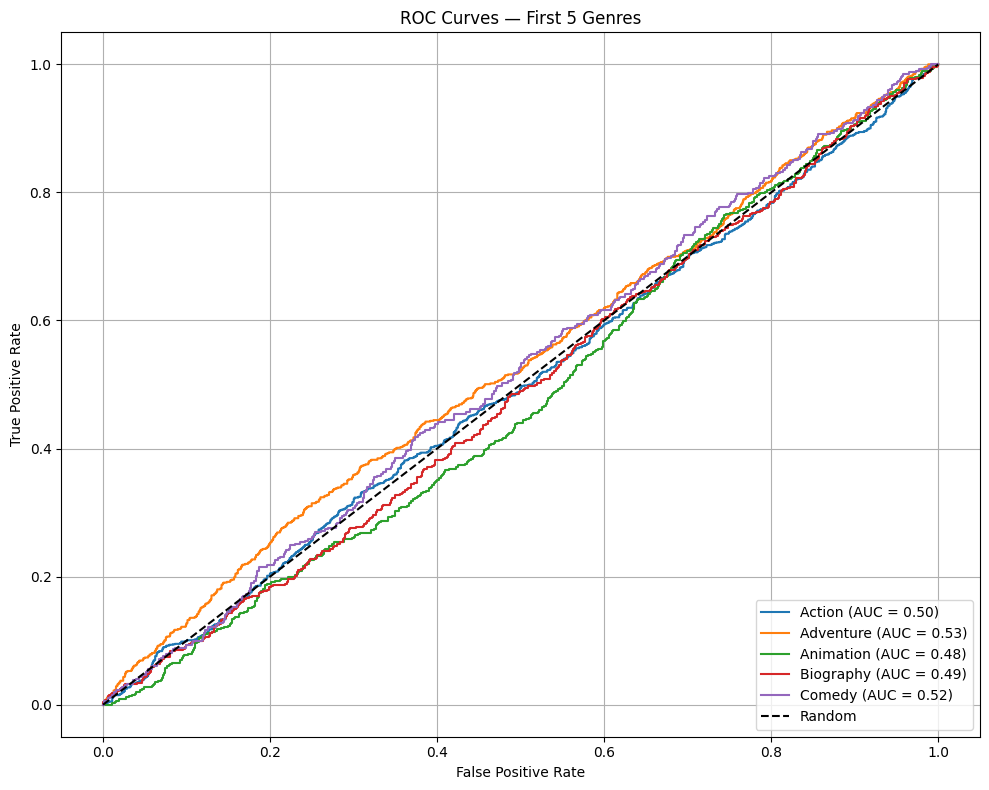

In [17]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for i in range(5):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{genre_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — First 5 Genres')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig("poster_roc curve")
plt.show()


In [18]:
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss
import numpy as np

assert y_true.shape == y_pred.shape, "Shapes of y_true and y_pred must match"

f1_micro = f1_score(y_true, y_pred, average='micro', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)

precision = precision_score(y_true, y_pred, average='micro', zero_division=0)
recall = recall_score(y_true, y_pred, average='micro', zero_division=0)

hamming = hamming_loss(y_true, y_pred)

print("Evaluation Metrics:")
print(f"F1 Score (Micro): {f1_micro:.4f}")
print(f"F1 Score (Macro): {f1_macro:.4f}")
print(f"Precision (Micro): {precision:.4f}")
print(f"Recall (Micro): {recall:.4f}")
print(f"Hamming Loss: {hamming:.4f}")


Evaluation Metrics:
F1 Score (Micro): 0.1345
F1 Score (Macro): 0.1193
Precision (Micro): 0.0807
Recall (Micro): 0.4037
Hamming Loss: 0.5614


In [19]:
import numpy as np
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

genre_counts = np.sum(y_true, axis=0)
top5_indices = genre_counts.argsort()[-5:][::-1]
top5_genres = [genre_names[i] for i in top5_indices]

print("Top 5 Genres (Most Frequent):")
for i in top5_indices:
    print(f"{genre_names[i]}: {genre_counts[i]} samples")

classwise_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)

print("\nClass-wise F1 Scores (Top 5 Genres):")
for idx in top5_indices:
    print(f"{genre_names[idx]}: {classwise_f1[idx]:.4f}")


Top 5 Genres (Most Frequent):
Action: 1410.0 samples
Adventure: 855.0 samples
Biography: 529.0 samples
Animation: 518.0 samples
Comedy: 394.0 samples

Class-wise F1 Scores (Top 5 Genres):
Action: 0.1717
Adventure: 0.3497
Biography: 0.0561
Animation: 0.3315
Comedy: 0.0664


<module 'matplotlib.pyplot' from 'C:\\Users\\Lenovo\\AppData\\Roaming\\Python\\Python312\\site-packages\\matplotlib\\pyplot.py'>

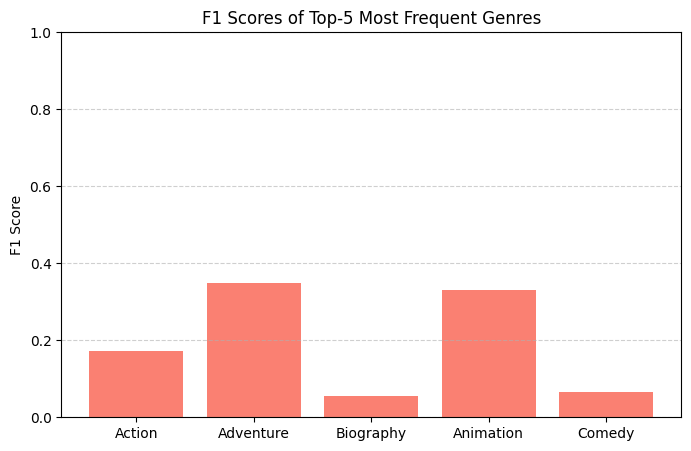

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score

genre_counts = np.sum(y_true, axis=0)
top5_indices = genre_counts.argsort()[-5:][::-1]

top5_genres = [genre_names[i] for i in top5_indices]

classwise_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)

top5_f1_scores = [classwise_f1[i] for i in top5_indices]

plt.figure(figsize=(8, 5))
plt.bar(top5_genres, top5_f1_scores, color='salmon')
plt.title("F1 Scores of Top-5 Most Frequent Genres")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig("posterF1scores_5genres_POSTER.png")
plt


<Figure size 1500x500 with 0 Axes>

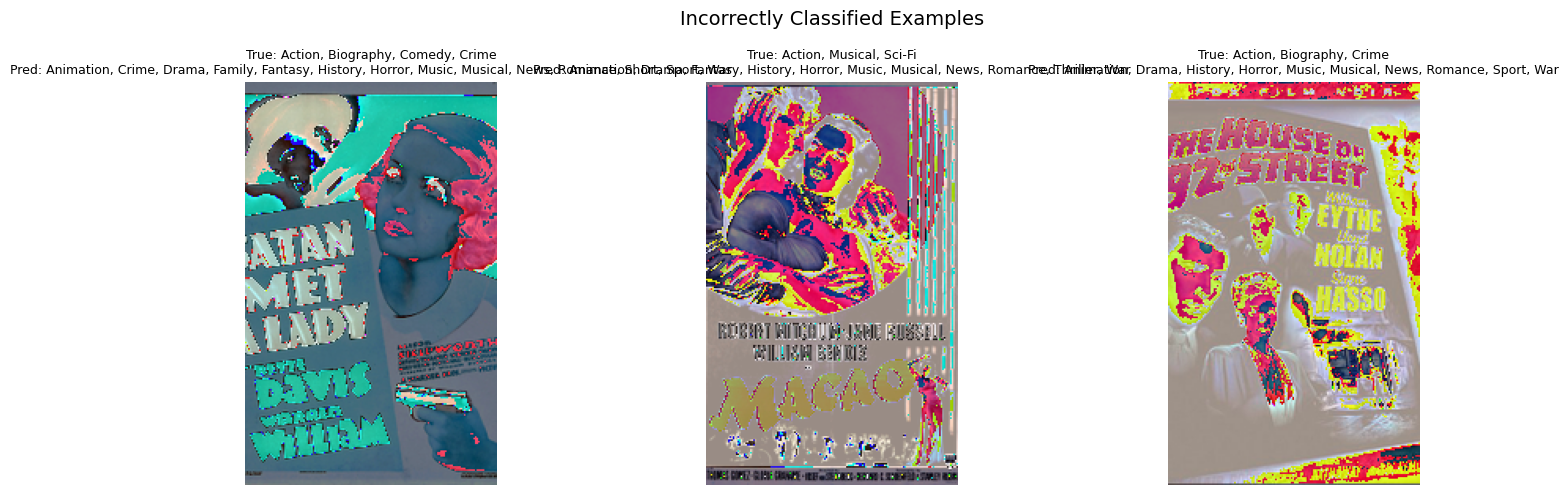

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def get_genre_names(binary_vector, genre_names):
    return [genre_names[i] for i in range(len(genre_names)) if binary_vector[i] == 1]

matches = np.all(y_true == y_pred, axis=1)
correct_indices = np.where(matches)[0][:3]      
incorrect_indices = np.where(~matches)[0][:3]    

def show_examples(indices, title):
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(indices):
        img = images[idx].transpose(1, 2, 0) 
        true_labels = get_genre_names(y_true[idx], genre_names)
        pred_labels = get_genre_names(y_pred[idx], genre_names)
        
        plt.subplot(1, 3, i+1)
        plt.imshow(img.astype(np.uint8))  
        plt.axis("off")
        plt.title(f"True: {', '.join(true_labels)}\nPred: {', '.join(pred_labels)}", fontsize=9)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig("posterincorrect_ex_POSTER")
    plt.show()

show_examples(correct_indices, "Correctly Classified Examples")

show_examples(incorrect_indices, "Incorrectly Classified Examples")


In [22]:
import pandas as pd

def vector_to_genres(vec):
    return [genre_names[i] for i in range(len(vec)) if vec[i] == 1]

logs = []
for i in range(len(y_true)):
    true_genres = vector_to_genres(y_true[i])
    pred_genres = vector_to_genres(y_pred[i])
    match = int(np.array_equal(y_true[i], y_pred[i]))
    logs.append({
        'index': i,
        'true_genres': ', '.join(true_genres),
        'pred_genres': ', '.join(pred_genres),
        'match': match
    })

df_logs = pd.DataFrame(logs)


df_logs.to_csv("Poster_only_Results.csv", index=False)

print("Poster_only_Results.csv saved successfully.")


Poster_only_Results.csv saved successfully.


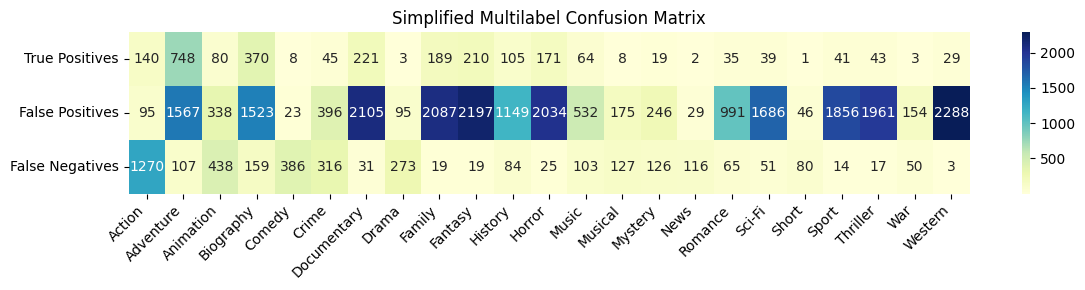

In [ ]:
import seaborn as sns
import numpy as np

TP = np.sum((y_true == 1) & (y_pred == 1), axis=0)
FP = np.sum((y_true == 0) & (y_pred == 1), axis=0)
FN = np.sum((y_true == 1) & (y_pred == 0), axis=0)

conf_matrix = np.vstack([TP, FP, FN]) 

plt.figure(figsize=(12, 3))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="YlGnBu", xticklabels=genre_names,
            yticklabels=['True Positives', 'False Positives', 'False Negatives'])
plt.title("Simplified Multilabel Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("poster_confusionmatrice_POSTER.png")

plt.show()


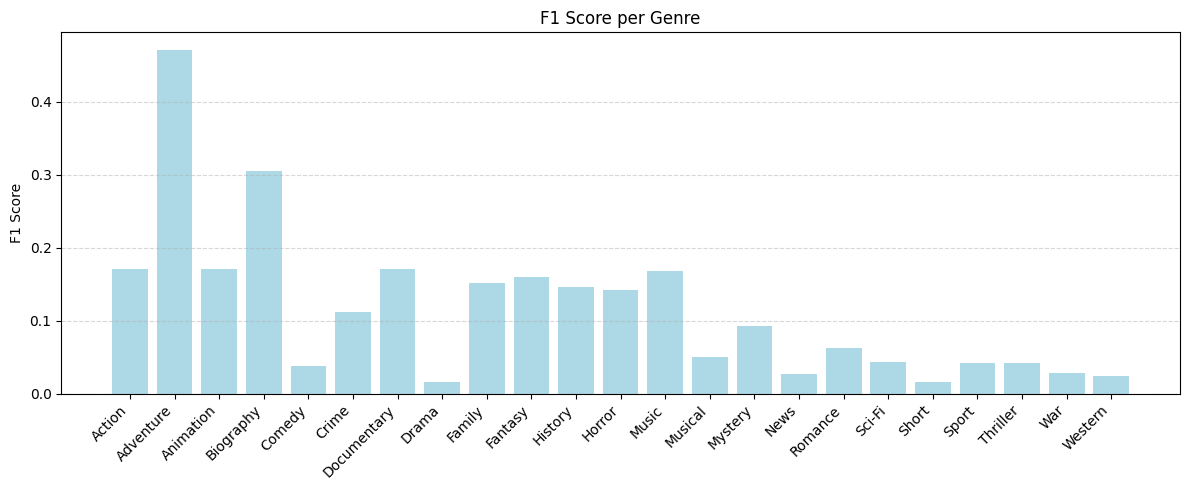

In [ ]:
from sklearn.metrics import f1_score

f1_per_class = f1_score(y_true, y_pred, average=None, zero_division=0)

plt.figure(figsize=(12, 5))
plt.bar(genre_names, f1_per_class, color="lightblue")
plt.ylabel("F1 Score")
plt.title("F1 Score per Genre")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("poster_F1scores_POSTER.png")
plt.show()


In [ ]:
import torch
import time
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

model = model.cpu()
model.eval()

sample_images = torch.tensor(images[:100], dtype=torch.float32)

dummy_labels = torch.zeros((sample_images.shape[0], 1))

dataset = TensorDataset(sample_images, dummy_labels)

def measure_inference_time(batch_size):
    loader = DataLoader(dataset, batch_size=batch_size)
    total_time = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch, _ in loader:
            start = time.time()
            _ = model(batch)
            end = time.time()

            total_time += (end - start)
            total_samples += batch.shape[0]

    avg_time = total_time / total_samples
    print(f"Avg Inference Time per sample (batch size={batch_size}): {avg_time:.6f} seconds")
    return avg_time

time_bs1 = measure_inference_time(batch_size=1)
time_bs16 = measure_inference_time(batch_size=16)


Avg Inference Time per sample (batch size=1): 0.019158 seconds
Avg Inference Time per sample (batch size=16): 0.022880 seconds


In [24]:
torch.save(model.state_dict(), "model.pt")
print(" Model saved as model.pt")


 Model saved as model.pt


In [25]:
import os

file_size_bytes = os.path.getsize("model.pt")
file_size_mb = file_size_bytes / (1024 * 1024)
print(f"model.pt size: {file_size_mb:.2f} MB")


model.pt size: 8.81 MB


In [26]:
!pip install torchsummary

from torchsummary import summary

model.cpu().eval()

summary(model, input_size=(3, 224, 224))


Defaulting to user installation because normal site-packages is not writeable
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 112, 112]             864
       BatchNorm2d-2         [-1, 32, 112, 112]              64
             ReLU6-3         [-1, 32, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]             288
       BatchNorm2d-5         [-1, 32, 112, 112]              64
             ReLU6-6         [-1, 32, 112, 112]               0
            Conv2d-7         [-1, 16, 112, 112]             512
       BatchNorm2d-8         [-1, 16, 112, 112]              32
  InvertedResidual-9         [-1, 16, 112, 112]               0
           Conv2d-10         [-1, 96, 112, 112]           1,536
      BatchNorm2d-11         [-1, 96, 112, 112]             192
            ReLU6-12         [-1, 96, 112, 112]               0
           Conv2d-13     

In [30]:
!pip install thop --quiet

from thop import profile

dummy_input = torch.randn(1, 3, 224, 224)

flops, params = profile(model, inputs=(dummy_input,), verbose=False)

print(f" Parameters: {params:,}")
print(f"FLOPs: {flops / 1e9:.2f} GFLOPs")


 Parameters: 2,253,335.0
FLOPs: 0.33 GFLOPs


In [ ]:
from sklearn.metrics import accuracy_score
import torch
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader: 
        images, labels = batch
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs)

        preds = (probs >= 0.5).int()
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())
        
y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

exact_match_accuracy = np.all(y_pred == y_true, axis=1).mean()
print(f"Exact Match Accuracy: {exact_match_accuracy:.4f}")

per_label_accuracy = (y_pred == y_true).mean()
print(f"Per-label Accuracy: {per_label_accuracy:.4f}")


Exact Match Accuracy: 0.0000
Per-label Accuracy: 0.1081


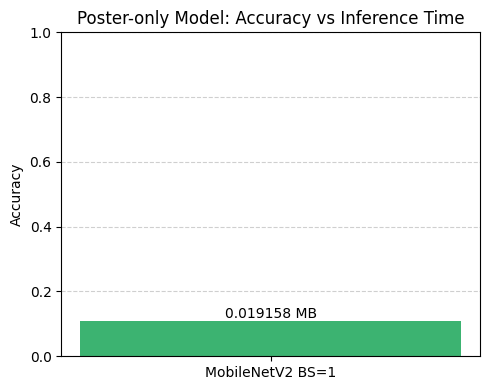

In [44]:
import matplotlib.pyplot as plt

model = ['MobileNetV2 BS=1']
Accuracy =[0.1081]         
Inference_Time = [0.019158]       

plt.figure(figsize=(5, 4))
bars = plt.bar(model, Accuracy, color='mediumseagreen', width=0.5)

for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
             f'{Inference_Time[i]} MB', ha='center', fontsize=10)

plt.title('Poster-only Model: Accuracy vs Inference Time')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


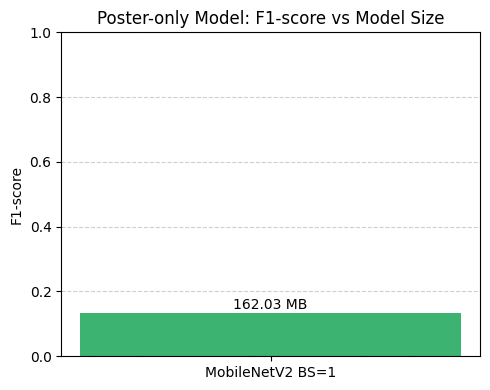

In [ ]:
import matplotlib.pyplot as plt

model = ['MobileNetV2 BS=1']
f1_score = [0.1345]         
model_size = [162.03]       

plt.figure(figsize=(5, 4))
bars = plt.bar(model, f1_score, color='mediumseagreen', width=0.5)

for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
             f'{model_size[i]} MB', ha='center', fontsize=10)

plt.title('Poster-only Model: F1-score vs Model Size')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [45]:
import pandas as pd

benchmark_data = {
    "Model": ["Image Only"],
    "F1-score": [0.1345],
    "Accuracy": [0.1081],
    "Inference Time (s/sample)": [0.022880],
    "Model Size (MB)": [162.03],
}

benchmark_df = pd.DataFrame(benchmark_data)
print("POSTER_Benchmark Summary Table")
display(benchmark_df)

benchmark_df.to_csv("POSTER_benchmark_summary.csv", index=False)


POSTER_Benchmark Summary Table


,Model,F1-score,Accuracy,Inference Time (s/sample),Model Size (MB)
0,Image Only,0.1345,0.1081,0.02288,162.03
